In [1]:
# Practical 8: Weather Data Analysis

# Step 1: Import Libraries
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# Step 2: Load Weather Data
with open("weather_sample.json") as f:
    data = json.load(f)

In [ ]:

# Step 3: Extract Data
df = pd.DataFrame([
    {
        'Time': x['dt_txt'],
        'Temperature': x['main']['temp'],
        'Humidity': x['main']['humidity'],
        'Wind': x['wind']['speed'],
        'Rain': x.get('rain', {}).get('3h', 0)
    }
    for x in data['list']
])

In [5]:
# Step 4: Clean Data
df['Time'] = pd.to_datetime(df['Time'])
df.dropna(inplace=True)

In [6]:

# Step 5: Analyze Data
print("Weather Summary:")
print(df.describe())

print("\nAverage Temperature:", df['Temperature'].mean())
print("Maximum Temperature:", df['Temperature'].max())
print("Minimum Temperature:", df['Temperature'].min())


Weather Summary:
                      Time  Temperature    Humidity        Wind        Rain
count                  160   160.000000  160.000000  160.000000  160.000000
mean   2024-10-10 22:30:00    24.320768   64.287500    4.453489    0.542848
min    2024-10-01 00:00:00    16.830043   40.000000    1.000762    0.000000
25%    2024-10-05 23:15:00    19.944740   53.000000    2.612492    0.000000
50%    2024-10-10 22:30:00    24.382744   65.000000    4.569696    0.000000
75%    2024-10-15 21:45:00    28.518589   75.000000    6.179150    0.000000
max    2024-10-20 21:00:00    31.650627   89.000000    7.927460    4.985149
std                    NaN     4.380793   13.669683    2.083189    1.283119

Average Temperature: 24.320768031554202
Maximum Temperature: 31.650626627903335
Minimum Temperature: 16.83004291544678


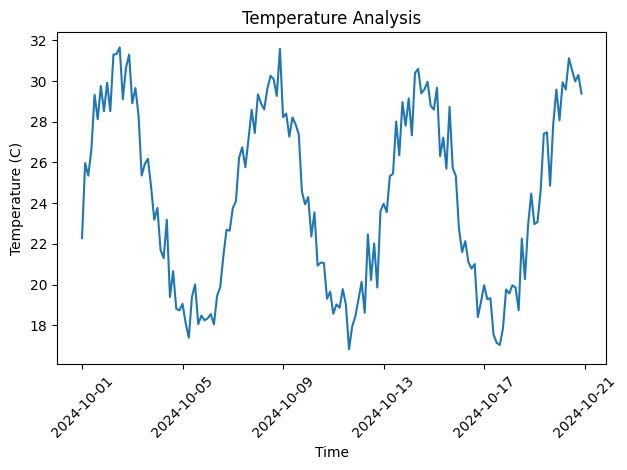

In [7]:
# Step 6: Visualize Temperature
plt.plot(df['Time'], df['Temperature'])
plt.title("Temperature Analysis")
plt.xlabel("Time")
plt.ylabel("Temperature (C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

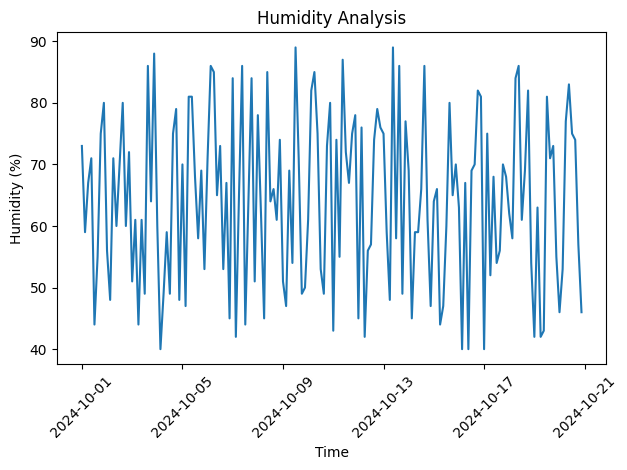

In [8]:
# Step 7: Visualize Humidity
plt.plot(df['Time'], df['Humidity'])
plt.title("Humidity Analysis")
plt.xlabel("Time")
plt.ylabel("Humidity (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

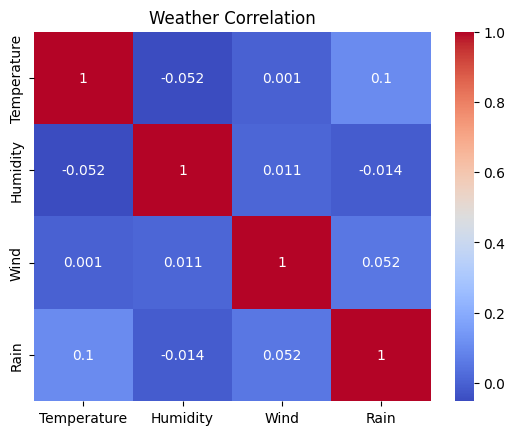

In [9]:

# Step 8: Correlation Heatmap
sns.heatmap(df[['Temperature', 'Humidity', 'Wind', 'Rain']].corr(),
            annot=True, cmap='coolwarm')

plt.title("Weather Correlation")
plt.show()


Weather Data:
                 Time  Temperature  Humidity  Wind  Rain
0 2026-11-01 15:00:00        29.56        68  3.51   0.0
1 2026-11-01 18:00:00        29.51        67  4.17   0.0
2 2026-11-01 21:00:00        28.69        70  3.06   0.0
3 2026-11-02 00:00:00        27.87        70  3.34   0.0
4 2026-11-02 03:00:00        28.14        69  2.60   0.0

Weather Statistics:
                      Time  Temperature   Humidity       Wind       Rain
count                   40     40.00000  40.000000  40.000000  40.000000
mean   2026-11-04 01:30:00     28.89275  67.875000   2.637000   0.014000
min    2026-11-01 15:00:00     26.80000  55.000000   0.500000   0.000000
25%    2026-11-02 20:15:00     28.17000  65.750000   1.962500   0.000000
50%    2026-11-04 01:30:00     29.01500  68.000000   2.480000   0.000000
75%    2026-11-05 06:45:00     29.66000  72.000000   3.345000   0.000000
max    2026-11-06 12:00:00     31.37000  75.000000   5.610000   0.270000
std                    NaN      1.0342

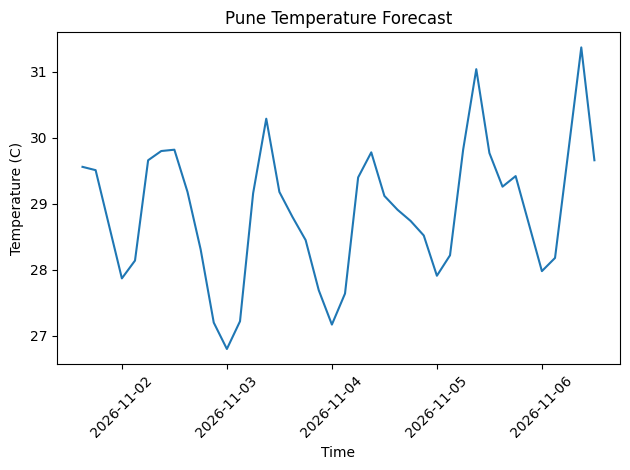

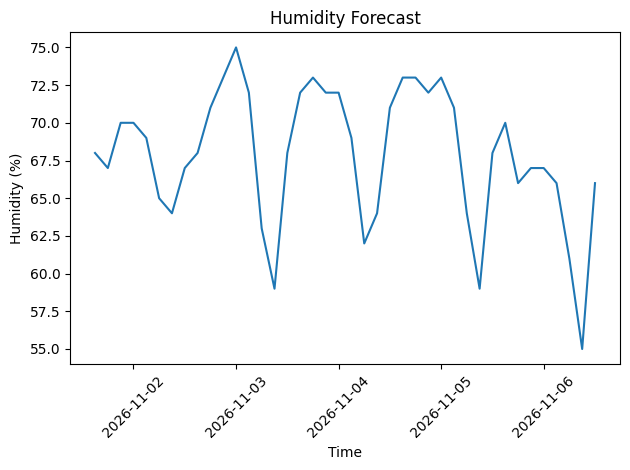

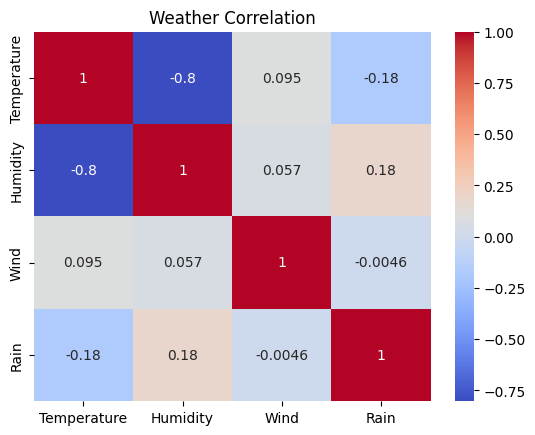


Weather data saved successfully!


In [11]:
# Practical 8: Weather Data Analysis Using API

# Step 1: Import Libraries
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 2: API Details
API_KEY = "d66f5a252fdab2a09e7ad0b7c6b193ed"
CITY = input("Enter city name: ")

# Step 3: Fetch Weather Data
url = "https://api.openweathermap.org/data/2.5/forecast"

params = {
    'q': CITY,
    'appid': API_KEY,
    'units': 'metric'
}

response = requests.get(url, params=params)
data = response.json()

# Check API response
if response.status_code != 200:
    print("API Error:", data.get('message', 'Unknown error'))

else:

    # Step 4: Extract Data
    df = pd.DataFrame([
        {
            'Time': x['dt_txt'],
            'Temperature': x['main']['temp'],
            'Humidity': x['main']['humidity'],
            'Wind': x['wind']['speed'],
            'Rain': x.get('rain', {}).get('3h', 0)
        }
        for x in data['list']
    ])

    # Step 5: Clean Data
    df['Time'] = pd.to_datetime(df['Time'])
    df.dropna(inplace=True)

    print("\nWeather Data:")
    print(df.head())

    # Step 6: Analyze Data
    print("\nWeather Statistics:")
    print(df.describe())

    print("\nAverage Temperature:", df['Temperature'].mean())
    print("Maximum Temperature:", df['Temperature'].max())
    print("Minimum Temperature:", df['Temperature'].min())

    # Step 7: Visualize Temperature
    plt.plot(df['Time'], df['Temperature'])
    plt.title("Pune Temperature Forecast")
    plt.xlabel("Time")
    plt.ylabel("Temperature (C)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Step 8: Visualize Humidity
    plt.plot(df['Time'], df['Humidity'])
    plt.title("Humidity Forecast")
    plt.xlabel("Time")
    plt.ylabel("Humidity (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Step 9: Correlation Heatmap
    sns.heatmap(
        df[['Temperature', 'Humidity', 'Wind', 'Rain']].corr(),
        annot=True,
        cmap='coolwarm'
    )

    plt.title("Weather Correlation")
    plt.show()

    # Step 10: Save Data
    df.to_csv("weather_data.csv", index=False)

    print("\nWeather data saved successfully!")